In [10]:
import json
import warnings
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
    fbeta_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_predict,
    train_test_split,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
import xgboost as xgb

warnings.filterwarnings("ignore")
RANDOM = 42

In [11]:
data= pd.read_csv('healthcare-dataset-stroke-data.csv')
print(data.head())


      id  gender   age  hypertension  heart_disease ever_married  \
0   9046    Male  67.0             0              1          Yes   
1  51676  Female  61.0             0              0          Yes   
2  31112    Male  80.0             0              1          Yes   
3  60182  Female  49.0             0              0          Yes   
4   1665  Female  79.0             1              0          Yes   

       work_type Residence_type  avg_glucose_level   bmi   smoking_status  \
0        Private          Urban             228.69  36.6  formerly smoked   
1  Self-employed          Rural             202.21   NaN     never smoked   
2        Private          Rural             105.92  32.5     never smoked   
3        Private          Urban             171.23  34.4           smokes   
4  Self-employed          Rural             174.12  24.0     never smoked   

   stroke  
0       1  
1       1  
2       1  
3       1  
4       1  


In [12]:
print(data.isna().sum())

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64


In [13]:
y=data['stroke']
X=data.drop(columns=['stroke','id'])

In [14]:
StrFeatures = X.select_dtypes(include=np.object_).columns.tolist()
for col in StrFeatures:
    print(f"Column: {col}, unique values: {X[col].unique()}")

Column: gender, unique values: <ArrowStringArray>
['Male', 'Female', 'Other']
Length: 3, dtype: str
Column: ever_married, unique values: <ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str
Column: work_type, unique values: <ArrowStringArray>
['Private', 'Self-employed', 'Govt_job', 'children', 'Never_worked']
Length: 5, dtype: str
Column: Residence_type, unique values: <ArrowStringArray>
['Urban', 'Rural']
Length: 2, dtype: str
Column: smoking_status, unique values: <ArrowStringArray>
['formerly smoked', 'never smoked', 'smokes', 'Unknown']
Length: 4, dtype: str


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM, stratify=y
)

In [16]:
categorical_features = [
    "gender",
    "ever_married",
    "work_type",
    "Residence_type",
    "smoking_status",
]
numerical_features = ["age", "avg_glucose_level", "bmi"]
binary_features = ["hypertension", "heart_disease"]

In [17]:
categorical_pipeline = Pipeline(
    [("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]
)

numerical_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

transformer = ColumnTransformer(
    [
        ("categorical", categorical_pipeline, categorical_features),
        ("numerical", numerical_pipeline, numerical_features),
        ("binary", "passthrough", binary_features),
    ]
)

In [18]:
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight = neg_count / pos_count

models = {
    "Random Forest": (
        RandomForestClassifier(random_state=RANDOM, class_weight="balanced"),
        {
            "classifier__n_estimators": [100, 200, 300],
            "classifier__max_depth": [None, 10, 20],
            "classifier__min_samples_split": [2, 5, 10],
            "classifier__max_features": ["sqrt", "log2"],
        },
    ),
    "Logistic Regression": (
        LogisticRegression(
            random_state=RANDOM, class_weight="balanced", max_iter=1000
        ),
        {
            "classifier__C": [0.01, 0.1, 1, 10, 100],
            "classifier__solver": ["liblinear", "saga"],
        },
    ),
    "Support Vector Machine": (
        SVC(random_state=RANDOM, class_weight="balanced", probability=True),
        {
            "classifier__C": [0.1, 1, 10],
            "classifier__kernel": ["linear", "rbf"],
            "classifier__gamma": ["scale", "auto"],
        },
    ),
    "Gaussian Naive Bayes": (
        GaussianNB(),
        {"classifier__var_smoothing": [1e-09, 1e-08, 1e-07, 1e-06, 1e-05]},
    ),
    "XGBoost": (
        xgb.XGBClassifier(
            random_state=RANDOM,
            eval_metric="logloss",
            scale_pos_weight=scale_pos_weight,
        ),
        {
            "classifier__n_estimators": [100, 200, 300],
            "classifier__max_depth": [3, 5, 7],
            "classifier__learning_rate": [0.01, 0.1, 0.2],
            "classifier__subsample": [0.8, 0.9, 1.0],
            "classifier__colsample_bytree": [0.8, 0.9, 1.0],
        },
    ),
}

In [19]:
def find_optimal_threshold_oof(
    pipeline, X_tr, y_tr, cv, model_name="Model", plot=True
):
    oof_probs = cross_val_predict(
        pipeline, X_tr, y_tr, cv=cv, method="predict_proba", n_jobs=-1
    )[:, 1]

    precision, recall, thresholds = precision_recall_curve(y_tr, oof_probs)
    valid_precision = precision[:-1]
    valid_recall = recall[:-1]

    f2_scores = np.divide(
        5 * valid_precision * valid_recall,
        4 * valid_precision + valid_recall,
        out=np.zeros_like(valid_precision),
        where=(4 * valid_precision + valid_recall) != 0,
    )

    optimal_idx = np.argmax(f2_scores)
    best_thresh = float(thresholds[optimal_idx])
    best_oof_f2 = float(f2_scores[optimal_idx])

    print(
        f"[{model_name}] Optimal Threshold (da Train OOF): {best_thresh:.3f} | Train OOF F2: {best_oof_f2:.4f}"
    )

    if plot:
        plt.figure(figsize=(7, 4))
        plt.plot(
            thresholds,
            f2_scores,
            label="Train OOF F2-Score",
            color="#2ca02c",
        )
        plt.axvline(
            x=best_thresh,
            color="red",
            linestyle="--",
            label=f"Optimal Threshold ({best_thresh:.2f})",
        )
        plt.title(f"Threshold Optimization (Out-of-Fold) - {model_name}")
        plt.xlabel("Classification Threshold")
        plt.ylabel("F2-Score")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.show()

    return best_thresh


--- Training Random Forest ---


Best parameters: {'classifier__max_depth': None, 'classifier__max_features': 'sqrt', 'classifier__min_samples_split': 10, 'classifier__n_estimators': 200}
[Random Forest] Optimal Threshold (da Train OOF): 0.320 | Train OOF F2: 0.4058


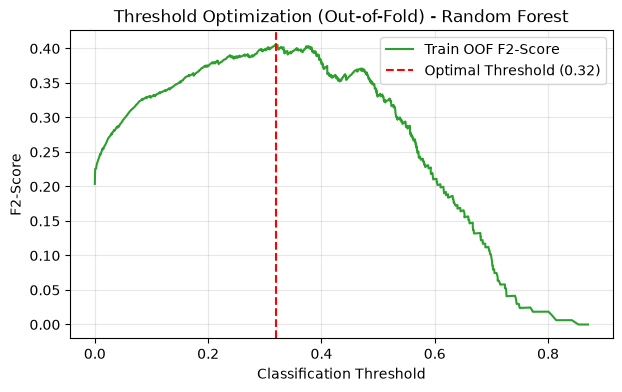

Test Set Results (Random Forest) -> F2: 0.4343 | Recall: 0.8200 | Precision: 0.1507
              precision    recall  f1-score   support

           0       0.99      0.76      0.86       972
           1       0.15      0.82      0.25        50

    accuracy                           0.77      1022
   macro avg       0.57      0.79      0.56      1022
weighted avg       0.95      0.77      0.83      1022


--- Training Logistic Regression ---
Best parameters: {'classifier__C': 1, 'classifier__solver': 'saga'}
[Logistic Regression] Optimal Threshold (da Train OOF): 0.564 | Train OOF F2: 0.4070


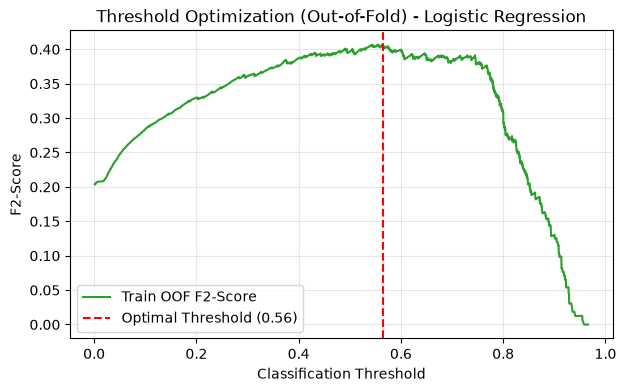

Test Set Results (Logistic Regression) -> F2: 0.4454 | Recall: 0.8000 | Precision: 0.1606
              precision    recall  f1-score   support

           0       0.99      0.78      0.87       972
           1       0.16      0.80      0.27        50

    accuracy                           0.79      1022
   macro avg       0.57      0.79      0.57      1022
weighted avg       0.95      0.79      0.84      1022


--- Training Support Vector Machine ---
Best parameters: {'classifier__C': 0.1, 'classifier__gamma': 'auto', 'classifier__kernel': 'rbf'}
[Support Vector Machine] Optimal Threshold (da Train OOF): 0.074 | Train OOF F2: 0.4126


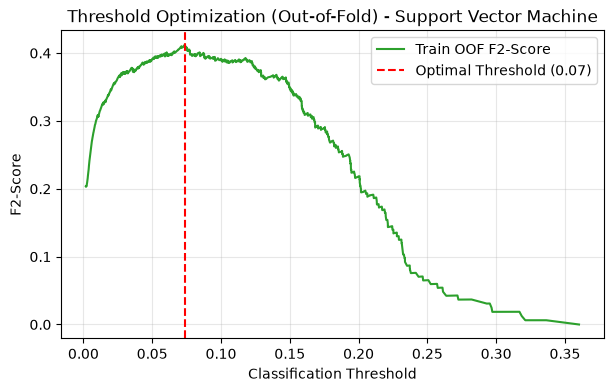

Test Set Results (Support Vector Machine) -> F2: 0.4493 | Recall: 0.7800 | Precision: 0.1667
              precision    recall  f1-score   support

           0       0.99      0.80      0.88       972
           1       0.17      0.78      0.27        50

    accuracy                           0.80      1022
   macro avg       0.58      0.79      0.58      1022
weighted avg       0.95      0.80      0.85      1022


--- Training Gaussian Naive Bayes ---
Best parameters: {'classifier__var_smoothing': 1e-08}
[Gaussian Naive Bayes] Optimal Threshold (da Train OOF): 1.000 | Train OOF F2: 0.3180


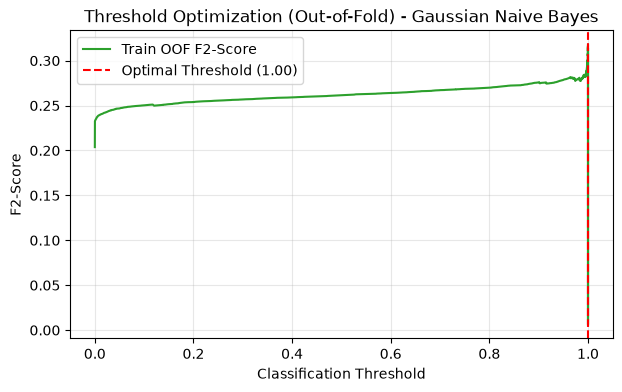

Test Set Results (Gaussian Naive Bayes) -> F2: 0.3616 | Recall: 0.7000 | Precision: 0.1232
              precision    recall  f1-score   support

           0       0.98      0.74      0.85       972
           1       0.12      0.70      0.21        50

    accuracy                           0.74      1022
   macro avg       0.55      0.72      0.53      1022
weighted avg       0.94      0.74      0.81      1022


--- Training XGBoost ---
Best parameters: {'classifier__colsample_bytree': 0.8, 'classifier__learning_rate': 0.1, 'classifier__max_depth': 7, 'classifier__n_estimators': 100, 'classifier__subsample': 0.8}
[XGBoost] Optimal Threshold (da Train OOF): 0.184 | Train OOF F2: 0.3999


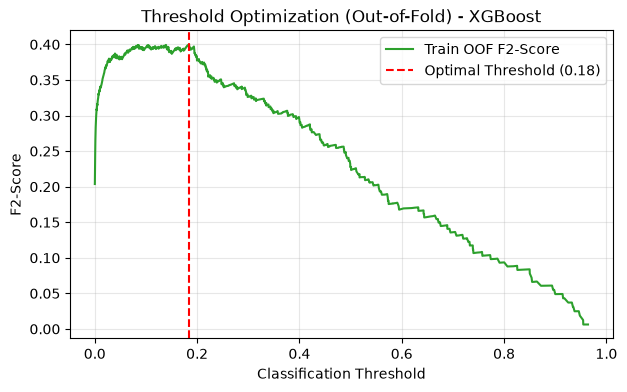

Test Set Results (XGBoost) -> F2: 0.3784 | Recall: 0.5600 | Precision: 0.1647
              precision    recall  f1-score   support

           0       0.97      0.85      0.91       972
           1       0.16      0.56      0.25        50

    accuracy                           0.84      1022
   macro avg       0.57      0.71      0.58      1022
weighted avg       0.93      0.84      0.88      1022



In [20]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM)
models_score = {}

for model_name, (clf, params) in models.items():
    print(f"\n--- Training {model_name} ---")
    pipe = Pipeline([("preprocessor", transformer), ("classifier", clf)])

    # Usiamo 'average_precision' (PR-AUC) per non dipendere dalla soglia 0.5 durante il tuning
    grid_search = GridSearchCV(
        pipe, params, cv=skf, scoring="average_precision", n_jobs=-1
    )
    grid_search.fit(X_train, y_train)
    best_pipe = grid_search.best_estimator_
    print(f"Best parameters: {grid_search.best_params_}")

    # Calcoliamo la soglia ottimale SOLO su X_train (Out-Of-Fold)
    opt_threshold = find_optimal_threshold_oof(
        best_pipe, X_train, y_train, cv=skf, model_name=model_name
    )

    # Valutazione finale imparziale su X_test
    test_probs = best_pipe.predict_proba(X_test)[:, 1]
    y_test_pred = (test_probs >= opt_threshold).astype(int)

    test_f2 = fbeta_score(y_test, y_test_pred, beta=2)
    test_recall = recall_score(y_test, y_test_pred)
    test_precision = precision_score(y_test, y_test_pred, zero_division=0)

    print(
        f"Test Set Results ({model_name}) -> F2: {test_f2:.4f} | Recall: {test_recall:.4f} | Precision: {test_precision:.4f}"
    )
    print(classification_report(y_test, y_test_pred))

    models_score[model_name] = {
        "F2 Score": round(float(test_f2), 4),
        "Recall": round(float(test_recall), 4),
        "Precision": round(float(test_precision), 4),
        "Optimal Threshold": round(float(opt_threshold), 3),
    }

In [21]:
with open("models_score.json", "w") as f:
    json.dump(models_score, f, indent=4)
